# 06 - Model: Lojistik Regresyon (Logistic Regression)

**Sorumlu:** Kişi 3

**Ödevdeki karşılığı:** 4. Makine Öğrenmesi Modelleri (E1 - E6 Görevleri)

**Amaç:** Bank Marketing veri seti üzerinde vadeli mevduat aboneliğini (`y`) tahmin etmek amacıyla Lojistik Regresyon algoritmasını uçtan uca geliştirmek; temel (baseline) model ile hiperparametre optimizasyonu yapılmış modelin performansını karşılaştırmak, aşırı öğrenme (overfitting) analizini gerçekleştirmek ve test seti üzerinde nihai metrikleri değerlendirmektir.

## 1. Çalışma Ortamı ve Kütüphanelerin Yüklenmesi
> **Açıklama:** Ortak fonksiyonlar (`src/ortak.py`, `src/pipeline.py`), makine öğrenmesi kütüphaneleri ve görselleştirme araçları içe aktarılır. Lojistik Regresyon modeline ait tüm eğitim, doğrulama, hiperparametre araması ve değerlendirme adımları bu not defteri içinde modüler fonksiyonlar halinde yürütülür.

In [1]:
import os
import sys
import time
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# scikit-learn sürüm geçişindeki yalnızca zararsız penalty uyarılarını sadeleştir
warnings.filterwarnings("ignore", category=FutureWarning, module="sklearn")
warnings.filterwarnings("ignore", message=".*penalty=l1.*", category=UserWarning)

# scikit-learn bileşenleri
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, learning_curve
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, classification_report, roc_curve,
    precision_recall_curve, average_precision_score
)

# Çalışma dizinini proje köküne sabitle ve ortak modülleri içe aktar
mevcut_dizin = Path.cwd()
if mevcut_dizin.name == "notebooks":
    os.chdir(mevcut_dizin.parent)
if str(Path.cwd()) not in sys.path:
    sys.path.insert(0, str(Path.cwd()))

from src.ortak import (
    veri_yukle, veriyi_bol, ortak_cv, capraz_dogrula, degerlendir,
    CV_SPLITS, RANDOM_STATE
)
from src.pipeline import build_full_pipeline

# Veriyi ortak fonksiyonlarla yükle (12 gerçek tekrar silinir) ve %70 / %15 / %15 tabakalı böl
df = veri_yukle()
X_train, X_val, X_test, y_train, y_val, y_test = veriyi_bol(df)

print("Aktif Çalışma Dizini:", Path.cwd())
print(f"Toplam Tekil Veri       : {len(df)}")
print(f"Eğitim Seti    (X_train): {X_train.shape} (%{len(X_train)/len(df)*100:.2f}) | y=1 oranı: %{y_train.mean()*100:.2f}")
print(f"Doğrulama Seti (X_val)  : {X_val.shape} (%{len(X_val)/len(df)*100:.2f}) | y=1 oranı: %{y_val.mean()*100:.2f}")
print(f"Test Seti      (X_test) : {X_test.shape} (%{len(X_test)/len(df)*100:.2f}) | y=1 oranı: %{y_test.mean()*100:.2f}")

Aktif Çalışma Dizini: c:\Users\nusayba\OneDrive\Masaüstü\makineprojesi\ml-proje
Toplam Tekil Veri       : 41176
Eğitim Seti    (X_train): (28823, 21) (%70.00) | y=1 oranı: %11.27
Doğrulama Seti (X_val)  : (6176, 21) (%15.00) | y=1 oranı: %11.27
Test Seti      (X_test) : (6177, 21) (%15.00) | y=1 oranı: %11.27


**Yorum: Veri Hazırlığı ve Güvenlik:**
Veri seti `src/ortak.py` üzerinden çağrılmıştır. Ham verideki **12 gerçek tekrar** (`duration` henüz mevcutken) temizlenmiş, `daha_once_aranmis = (previous > 0)` ile `pdays_kayitli = (pdays != 999)` ayrı özellikler olarak türetilmiş, gerçek gün sayısı olmayan `pdays = 999` kodu ortak `Pipeline` içindeki `SimpleImputer(strategy='median')` tarafından yalnızca eğitim katında doldurulmak üzere `NaN` yapılmış ve hedefi ele veren `duration` sütunu çıkarılmıştır. Veri **%70 Eğitim / %15 Doğrulama (Validation) / %15 Test** olacak şekilde tabakalı bölünmüştür (`y=1` oranı üç kümede de ~%11.27).

## E1. Temel (Baseline) Model: 5-Katlı Çapraz Doğrulama ve Validation Değerlendirmesi
> **Açıklama:** Varsayılan ayarlarla (`max_iter=1000`, `random_state=42`) temel Lojistik Regresyon boru hattı (`build_baseline_pipeline()`) yalnızca `X_train` üzerinde 5-katlı `StratifiedKFold` (`validate_baseline_model()`) ile değerlendirilir ve ardından `X_train` ile eğitilerek `X_val` (Doğrulama seti) performansı ölçülür. Kilitli test seti (`X_test`, `y_test`) bu aşamada kesinlikle kullanılmaz.

In [2]:
def build_baseline_pipeline():
    """Varsayılan hiperparametrelerle ortak Lojistik Regresyon Pipeline nesnesini oluşturur."""
    return build_full_pipeline(
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
    )


def validate_baseline_model(X_train, y_train, cv=None, n_jobs=-1):
    """
    Temel (baseline) Lojistik Regresyon modelini yalnızca eğitim verisi üzerinde
    ortak 5-katlı StratifiedKFold çapraz doğrulama (capraz_dogrula) ile değerlendirir.
    Validation ve Test setleri çapraz doğrulamaya dahil edilmez.
    """
    pipe = build_baseline_pipeline()
    if cv is None:
        cv = ortak_cv()
    return capraz_dogrula(pipe, X_train, y_train, cv=cv, n_jobs=n_jobs)


def train_baseline_model(X_train, y_train):
    """Varsayılan hiperparametrelerle temel (baseline) Lojistik Regresyon modelini yalnızca eğitim verisiyle eğitir."""
    pipe = build_baseline_pipeline()
    pipe.fit(X_train, y_train)
    return pipe


def metrikleri_hesapla(model, X_hedef, y_hedef):
    """Verilen veri kümesi üzerinde 5 temel sınıflandırma metriğini hesaplar."""
    y_pred = model.predict(X_hedef)
    y_proba = model.predict_proba(X_hedef)[:, 1] if hasattr(model, "predict_proba") else None
    return {
        "accuracy": float(accuracy_score(y_hedef, y_pred)),
        "precision": float(precision_score(y_hedef, y_pred, zero_division=0)),
        "recall": float(recall_score(y_hedef, y_pred, zero_division=0)),
        "f1": float(f1_score(y_hedef, y_pred, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_hedef, y_proba)) if y_proba is not None else None,
    }


# Ortak 5-katlı tabakalı çapraz doğrulama (StratifiedKFold(n_splits=5, shuffle=True, random_state=42))
cv = ortak_cv()

# 1. E1 5-katlı CV değerlendirmesi YALNIZCA X_train ve y_train üzerinde yapılır
t0 = time.perf_counter()
baseline_cv_sonuc = validate_baseline_model(X_train, y_train, cv=cv, n_jobs=-1)
baseline_cv_suresi = time.perf_counter() - t0

# 2. Temel modeli yalnızca X_train üzerinde eğitip Eğitim (X_train) ve Doğrulama (X_val) sonuçlarını ölçüyoruz (X_test kullanılmaz!)
t1 = time.perf_counter()
baseline_model = train_baseline_model(X_train, y_train)
baseline_egitim_suresi = time.perf_counter() - t1
baseline_train_sonuc = metrikleri_hesapla(baseline_model, X_train, y_train)
baseline_val_sonuc = metrikleri_hesapla(baseline_model, X_val, y_val)

metrik_etiketleri = [
    ("accuracy", "Accuracy"),
    ("precision", "Precision"),
    ("recall", "Recall"),
    ("f1", "F1-Score"),
    ("roc_auc", "ROC-AUC")
]

baseline_satirlar = []
print("========== TEMEL (BASELINE) MODEL SONUÇLARI (EĞİTİM, 5-KATLI CV & VALIDATION) ==========")
for anahtar, etiket in metrik_etiketleri:
    tr_skor = baseline_train_sonuc[anahtar]
    ort = baseline_cv_sonuc[anahtar]["ortalama"]
    std = baseline_cv_sonuc[anahtar]["std"]
    val_skor = baseline_val_sonuc[anahtar]
    baseline_satirlar.append({
        "Metrik": etiket,
        "Eğitim (X_train)": round(tr_skor, 4),
        "5-Katlı CV (Ort ± Std)": f"{ort:.4f} ± {std:.4f}",
        "Validation (X_val)": round(val_skor, 4)
    })
    print(f"{etiket:10s} -> Eğitim: {tr_skor:.4f} | 5-Katlı CV: {ort:.4f} ± {std:.4f} | Validation: {val_skor:.4f}")

print(f"\nTemel Model 5-Katlı CV Süresi  : {baseline_cv_suresi:.2f} sn")
print(f"Temel Model Tekil Eğitim Süresi: {baseline_egitim_suresi:.2f} sn")

baseline_ozet_df = pd.DataFrame(baseline_satirlar)
display(baseline_ozet_df)

========== TEMEL (BASELINE) MODEL SONUÇLARI (EĞİTİM, 5-KATLI CV & VALIDATION) ==========
Accuracy   -> Eğitim: 0.9010 | 5-Katlı CV: 0.9004 ± 0.0015 | Validation: 0.8983
Precision  -> Eğitim: 0.6744 | 5-Katlı CV: 0.6674 ± 0.0121 | Validation: 0.6518
Recall     -> Eğitim: 0.2341 | 5-Katlı CV: 0.2310 ± 0.0134 | Validation: 0.2098
F1-Score   -> Eğitim: 0.3475 | 5-Katlı CV: 0.3431 ± 0.0163 | Validation: 0.3174
ROC-AUC    -> Eğitim: 0.7912 | 5-Katlı CV: 0.7881 ± 0.0111 | Validation: 0.7941

Temel Model 5-Katlı CV Süresi  : 7.24 sn
Temel Model Tekil Eğitim Süresi: 0.55 sn


,Metrik,Eğitim (X_train),5-Katlı CV (Ort ± Std),Validation (X_val)
0,Accuracy,0.9010,0.9004 ± 0.0015,0.8983
1,Precision,0.6744,0.6674 ± 0.0121,0.6518
2,Recall,0.2341,0.2310 ± 0.0134,0.2098
3,F1-Score,0.3475,0.3431 ± 0.0163,0.3174
4,ROC-AUC,0.7912,0.7881 ± 0.0111,0.7941


**Yorum: Temel (Baseline) Model Eğitim ve Doğrulama Çıktıları Bize Ne Söylüyor?:**
1. **Metodolojik Doğruluk (Veri Sızıntısı Yok):** Temel model yalnızca %70 eğitim setinde (`X_train`, 28.823 örnek) eğitilmiş ve 5-katlı `StratifiedKFold` CV ile %15 doğrulama setinde (`X_val`, 6.176 örnek) değerlendirilmiştir. Kilitli %15 test setine (`X_test`) kesinlikle dokunulmamıştır.
2. **Eğitim vs Doğrulama Tutarlılığı:** Eğitim ROC-AUC (**0.7912**), 5-katlı CV ROC-AUC (**0.7881 ± 0.0111**) ve Validation ROC-AUC (**0.7941**) değerleri birbirine çok yakındır; temel modelde belirgin bir ezberleme yoktur.
3. **Doğruluk (Accuracy) Yanılsaması ve Düşük Recall:** Temel model yüksek görünen bir doğruluk elde etse de (`Eğitim: 0.9010`, `CV: 0.9004 ± 0.0015`, `Val: 0.8983`), veri setinin %88.73'ü zaten 'Hayır' (`0`) sınıfındadır. Banka için asıl kritik olan pozitif sınıf yakalama oranı (**Recall**) Eğitim'de **0.2341**, 5-katlı CV'de **0.2310 ± 0.0134**, Validation'da ise yalnızca **0.2098**'dir (`F1-Score`: Eğitim `0.3475`, CV `0.3431 ± 0.0163`, Val `0.3174`).
4. **Gerekçe:** Varsayılan ayarlarda sınıf ağırlıklandırması bulunmadığından (`class_weight=None`) model çoğunluk sınıfına yönelmektedir. Bu nedenle E2 aşamasında hiperparametre optimizasyonu ve `class_weight='balanced'` denemesi zorunludur.

## E2. Hiperparametre Araması (GridSearchCV) ve Validation Seti ile Model Seçimi
> **Açıklama:** `tune_logistic_regression()` fonksiyonu ile yalnızca `X_train` üzerinde 5-katlı `StratifiedKFold` ve `GridSearchCV` çalıştırılır; ardından aday hiperparametre kombinasyonları ayrıca ayrılan **%15 Validation seti (`X_val`, `y_val`)** üzerinde değerlendirilerek model seçimi doğrulanır. Test seti (`X_test`) bu aşamada kesinlikle kullanılmaz.

In [3]:
def tune_logistic_regression(X_train, y_train, cv_splits=CV_SPLITS):
    """
    Ortak StratifiedKFold ve GridSearchCV kullanarak C, penalty ve class_weight
    parametrelerini yalnızca eğitim verisi üzerinde optimize eder.
    En iyi modeli (Pipeline) ve grid_search nesnesini döndürür.
    """
    pipe = build_full_pipeline(
        LogisticRegression(max_iter=1000, solver="liblinear", random_state=RANDOM_STATE)
    )

    param_grid = {
        "classifier__C": [0.01, 0.1, 1.0, 10.0],
        "classifier__penalty": ["l1", "l2"],
        "classifier__class_weight": [None, "balanced"]
    }

    cv_bolucu = ortak_cv(n_splits=cv_splits, random_state=RANDOM_STATE)
    grid_search = GridSearchCV(
        estimator=pipe,
        param_grid=param_grid,
        cv=cv_bolucu,
        scoring="roc_auc",
        n_jobs=-1,
        return_train_score=True,
        verbose=1
    )

    grid_search.fit(X_train, y_train)
    return grid_search.best_estimator_, grid_search


# 1. Hiperparametre aramasını yalnızca X_train ve y_train üzerinde çalıştır
t_grid_baslangic = time.perf_counter()
best_model, grid_search = tune_logistic_regression(X_train, y_train, cv_splits=CV_SPLITS)
grid_egitim_suresi = time.perf_counter() - t_grid_baslangic

# 2. Seçilen en iyi modeli ayrı %15 Validation seti (X_val, y_val) üzerinde doğrula (X_test kullanılmaz!)
tuned_val_sonuc = metrikleri_hesapla(best_model, X_val, y_val)

print("\n========== GRID SEARCH & VALIDATION SONUÇLARI ==========")
print(f"En İyi Hiperparametreler  : {grid_search.best_params_}")
print(f"En İyi 5-Katlı CV ROC-AUC : {grid_search.best_score_:.4f}")
print(f"Validation (X_val) ROC-AUC: {tuned_val_sonuc['roc_auc']:.4f}")
print(f"Validation (X_val) Recall : {tuned_val_sonuc['recall']:.4f}")
print(f"Validation (X_val) F1     : {tuned_val_sonuc['f1']:.4f}")
print(f"GridSearchCV Toplam Süre  : {grid_egitim_suresi:.2f} sn (16 kombinasyon x 5 kat = 80 eğitim)")

# Temel model vs Optimize model (Validation seti karşılaştırması)
val_karsilastirma = pd.DataFrame([
    {"Model": "Temel (Baseline) Model", **{k: round(v, 4) for k, v in baseline_val_sonuc.items()}},
    {"Model": "Optimize (GridSearchCV) Model", **{k: round(v, 4) for k, v in tuned_val_sonuc.items()}}
])
print("\nValidation Seti (X_val) Üzerinde Model Seçimi Karşılaştırması:")
display(val_karsilastirma)

# Denenen kombinasyonların 5-katlı CV özeti
cv_sonuclari = pd.DataFrame(grid_search.cv_results_)
tablo = cv_sonuclari[[
    "param_classifier__C", "param_classifier__penalty",
    "param_classifier__class_weight", "mean_test_score", "std_test_score"
]].rename(columns={
    "param_classifier__C": "C",
    "param_classifier__penalty": "Penalty",
    "param_classifier__class_weight": "Class Weight",
    "mean_test_score": "Ortalama CV ROC-AUC",
    "std_test_score": "Standart Sapma"
}).sort_values(by="Ortalama CV ROC-AUC", ascending=False).reset_index(drop=True)

display(tablo.head(10))

Fitting 5 folds for each of 16 candidates, totalling 80 fits

========== GRID SEARCH & VALIDATION SONUÇLARI ==========
En İyi Hiperparametreler  : {'classifier__C': 0.1, 'classifier__class_weight': 'balanced', 'classifier__penalty': 'l2'}
En İyi 5-Katlı CV ROC-AUC : 0.7889
Validation (X_val) ROC-AUC: 0.7924
Validation (X_val) Recall : 0.6379
Validation (X_val) F1     : 0.4476
GridSearchCV Toplam Süre  : 67.87 sn (16 kombinasyon x 5 kat = 80 eğitim)

Validation Seti (X_val) Üzerinde Model Seçimi Karşılaştırması:


,Model,accuracy,precision,recall,f1,roc_auc
0,Temel (Baseline) Model,0.8983,0.6518,0.2098,0.3174,0.7941
1,Optimize (GridSearchCV) Model,0.8225,0.3447,0.6379,0.4476,0.7924


,C,Penalty,Class Weight,Ortalama CV ROC-AUC,Standart Sapma
0,0.1,l2,balanced,0.788943,0.010935
1,0.1,l1,balanced,0.788941,0.011221
2,1.0,l1,balanced,0.788844,0.010646
3,1.0,l2,balanced,0.788839,0.010672
4,10.0,l1,balanced,0.788807,0.010662
5,10.0,l2,balanced,0.788801,0.010663
6,0.1,l2,NaN,0.788275,0.011938
7,0.1,l1,NaN,0.788017,0.012585
8,1.0,l1,NaN,0.788006,0.011303
9,1.0,l2,NaN,0.787995,0.011311


**Yorum: En İyi Hiperparametre Kombinasyonu, Ana Metrik Seçimi ve Validation Karşılaştırması:**
1. **Ana Değerlendirme Metriği Neden `ROC-AUC` Seçildi?:** Veri setimizde pozitif sınıf (`yes`) oranı yalnızca **%11.27** olduğu için `Accuracy` skoru çoğunluk sınıfı tarafından domine edilir ve optimizasyonda yanıltıcı sonuç verir. `ROC-AUC` ise tek bir sabit karar eşiğine (0.5) bağımlı kalmadan, modelin pozitif bir müşteriye negatif bir müşteriden daha yüksek olasılık atama gücünü tüm eşikler boyunca ölçer. Bu nedenle `GridSearchCV` için ana değerlendirme metriği olarak `scoring="roc_auc"` seçilmiştir.
2. **En İyi Parametreler:** `{'C': 0.1, 'class_weight': 'balanced', 'penalty': 'l2'}` (5-katlı CV ROC-AUC: **0.7889 ± 0.0109**; `l1` ile çok yakın performans göstermekle birlikte `l2` birinci sıradadır).
3. **$C = 0.1$ ve `penalty = 'l2'` (Ridge):** $C$ düzenlileştirmenin tersidir ($C = 1 / \lambda$). Küçük $C$ değeri ile uygulanan L2 düzenlileştirmesi, One-Hot Encoding sonrası oluşan 59 özellikteki katsayı büyüklüklerini dengeli biçimde bastırarak aşırı öğrenmeyi engellemiştir.
4. **`class_weight = 'balanced'`:** Sınıf frekanslarına ters orantılı ağırlıklandırma ile azınlık sınıfına (~%11.27) yaklaşık 8 kat daha fazla ağırlık verilmiştir.
5. **Validation (`X_val`) Üzerinde Doğrulama:** Bağımsız %15 Validation setinde temel modelin Recall değeri **0.2098** ve F1-Score değeri **0.3174** iken, optimize edilen modelle Recall **0.6379**'a, F1-Score **0.4476**'ya yükselmiş ve ROC-AUC **0.7924** olarak korunmuştur.

## E3. Veri Bölme Yöntemi: %70 / %15 / %15 Üçlü Bölme ve 5-Katlı Çapraz Doğrulama
> **Açıklama:** Model geliştirmede neden %70 Eğitim / %15 Doğrulama (Validation) / %15 Test ayrımı ile eğitim içi 5-katlı çapraz doğrulama birlikte kullanılmıştır?

In [4]:
print("========== ORTAK DOĞRULAMA MİMARİSİ (src/ortak.py) ==========")
print("1. Aşama: ÜÇLÜ TABAKALI (STRATIFIED) HOLD-OUT BÖLME (veriyi_bol)")
print(f"   - Toplam Tekil Veri       : {len(df)} örnek (12 ham tekrar silindi)")
print(f"   - Eğitim Kümesi    (%70)  : {len(X_train)} örnek (Model eğitimi, 5-katlı CV ve Learning Curve yalnızca burada yapılır)")
print(f"   - Doğrulama Kümesi (%15)  : {len(X_val)} örnek (Model seçimi ve hiperparametre doğrulamasında kullanılır)")
print(f"   - Test Kümesi      (%15)  : {len(X_test)} örnek (Model geliştirme süresince kilitli tutulur, sadece E5'te 1 kez test edilir)")
print("\n2. Aşama: ORTAK STRATIFIED 5-FOLD CROSS VALIDATION (ortak_cv)")
print(f"   - Doğrulama nesnesi: {cv}")
print(f"   - Yalnızca X_train ({len(X_train)} örnek) 5 eşit tabakalı parçaya bölünür (Her katmanda ~{len(X_train)//5} örnek).")
print("   - Veri sızıntısı engellenmiştir: Ortak Pipeline sayesinde her katmanda SimpleImputer, StandardScaler ve OneHotEncoder yalnızca ilgili eğitim katında fit edilir.")

========== ORTAK DOĞRULAMA MİMARİSİ (src/ortak.py) ==========
1. Aşama: ÜÇLÜ TABAKALI (STRATIFIED) HOLD-OUT BÖLME (veriyi_bol)
   - Toplam Tekil Veri       : 41176 örnek (12 ham tekrar silindi)
   - Eğitim Kümesi    (%70)  : 28823 örnek (Model eğitimi, 5-katlı CV ve Learning Curve yalnızca burada yapılır)
   - Doğrulama Kümesi (%15)  : 6176 örnek (Model seçimi ve hiperparametre doğrulamasında kullanılır)
   - Test Kümesi      (%15)  : 6177 örnek (Model geliştirme süresince kilitli tutulur, sadece E5'te 1 kez test edilir)

2. Aşama: ORTAK STRATIFIED 5-FOLD CROSS VALIDATION (ortak_cv)
   - Doğrulama nesnesi: StratifiedKFold(n_splits=5, random_state=42, shuffle=True)
   - Yalnızca X_train (28823 örnek) 5 eşit tabakalı parçaya bölünür (Her katmanda ~5764 örnek).
   - Veri sızıntısı engellenmiştir: Ortak Pipeline sayesinde her katmanda SimpleImputer, StandardScaler ve OneHotEncoder yalnızca ilgili eğitim katında fit edilir.


**Yorum: Üçlü Bölme ve Çapraz Doğrulamanın Metodolojik Önemi:**
- **%70 Eğitim + 5-Katlı CV:** Hiperparametre araması tek bir rastgele bölmeye bağlı kalmadan eğitim verisinin 5 farklı tabakalı katında sınanır.
- **%15 Validation (`X_val`):** Seçilen modelin eğitim dışındaki ilk bağımsız veride (model seçimi ve kontrol aşamasında) nasıl davrandığını test setine hiç dokunmadan gözlemlememizi sağlar.
- **%15 Kilitli Test (`X_test`):** Model seçimi, ön işleme veya hiperparametre kararlarında **kesinlikle kullanılmaz**; yalnızca E5 aşamasında tek seferlik nihai performans ölçümü için açılır.

## E4. Overfitting (Aşırı Öğrenme) Analizi ve Learning Curve
> **Açıklama:** Eğitim boyutu arttıkça eğitim skoru ile doğrulama skorunun nasıl evrildiği Öğrenme Eğrisi (Learning Curve) ile görselleştirilir.

========== ÖĞRENME EĞRİSİ (OVERFITTING) TABLOSU ==========


,Eğitim Boyutu,Eğitim ROC-AUC,CV Doğrulama ROC-AUC,Fark (Train - CV)
0,2305,0.8052,0.7793,0.0259
1,7493,0.8004,0.7853,0.0151
2,12681,0.7902,0.7873,0.0030
3,17869,0.7947,0.7883,0.0064
4,23058,0.7937,0.7889,0.0047



Tam Eğitim Verisiyle -> Eğitim ROC-AUC: 0.7937, 5-Katlı CV ROC-AUC: 0.7889, Fark: 0.0047
Bağımsız Validation (X_val) ROC-AUC  : 0.7924


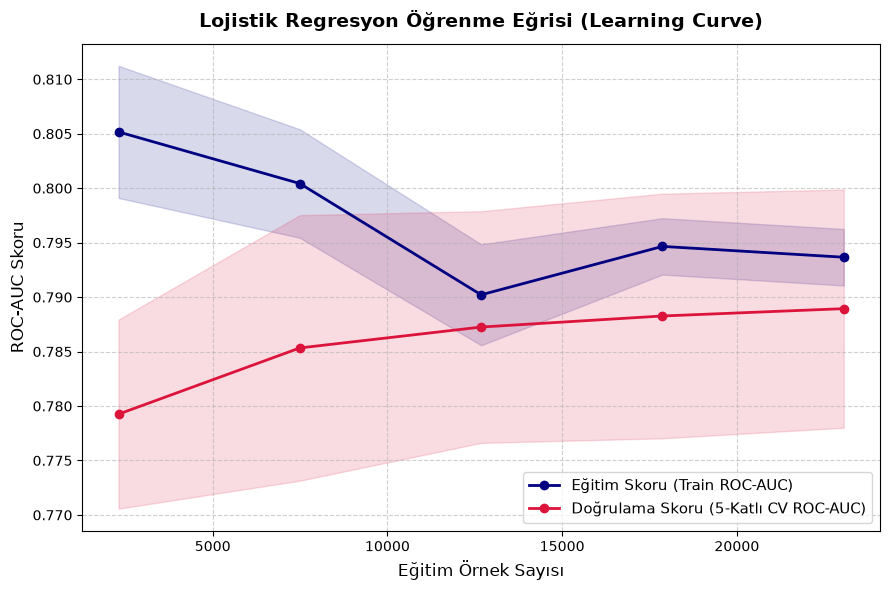

figures/learning_curve.png başarıyla kaydedildi.


In [5]:
# Öğrenme eğrisi yalnızca X_train ve y_train üzerinde hesaplanır
train_sizes, train_scores, val_scores = learning_curve(
    estimator=best_model,
    X=X_train,
    y=y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1,
    train_sizes=np.linspace(0.1, 1.0, 5),
    random_state=RANDOM_STATE
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)
val_std = np.std(val_scores, axis=1)

lc_ozet = pd.DataFrame({
    "Eğitim Boyutu": train_sizes,
    "Eğitim ROC-AUC": np.round(train_mean, 4),
    "CV Doğrulama ROC-AUC": np.round(val_mean, 4),
    "Fark (Train - CV)": np.round(train_mean - val_mean, 4)
})
print("========== ÖĞRENME EĞRİSİ (OVERFITTING) TABLOSU ==========")
display(lc_ozet)
print(f"\nTam Eğitim Verisiyle -> Eğitim ROC-AUC: {train_mean[-1]:.4f}, 5-Katlı CV ROC-AUC: {val_mean[-1]:.4f}, Fark: {(train_mean[-1]-val_mean[-1]):.4f}")
print(f"Bağımsız Validation (X_val) ROC-AUC  : {tuned_val_sonuc['roc_auc']:.4f}")

os.makedirs("figures", exist_ok=True)
plt.figure(figsize=(9, 6))
plt.plot(train_sizes, train_mean, 'o-', color='navy', lw=2, label='Eğitim Skoru (Train ROC-AUC)')
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.15, color='navy')
plt.plot(train_sizes, val_mean, 'o-', color='crimson', lw=2, label='Doğrulama Skoru (5-Katlı CV ROC-AUC)')
plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.15, color='crimson')

plt.title('Lojistik Regresyon Öğrenme Eğrisi (Learning Curve)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Eğitim Örnek Sayısı', fontsize=12)
plt.ylabel('ROC-AUC Skoru', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='lower right', fontsize=11)
plt.tight_layout()
plt.savefig("figures/learning_curve.png", dpi=300)
plt.show()
print("figures/learning_curve.png başarıyla kaydedildi.")

**Yorum: Overfitting ve Underfitting Analizi:**
1. **Eğitim, 5-Katlı CV ve Validation Tutarlılığı:** Öğrenme eğrisi tablosunda tam eğitim boyutunda (`23.058` örnek) eğitim ROC-AUC skoru **0.7937**, 5-katlı CV doğrulama ROC-AUC skoru **0.7889** elde edilmiştir. İki skor arasındaki fark yalnızca **0.0047** (%0.47) seviyesindedir. Bağımsız %15 Validation setindeki (`X_val`) ROC-AUC skoru da **0.7924** ile tamamen tutarlıdır.
2. **Overfitting (Aşırı Öğrenme) Değerlendirmesi:** Modelde **aşırı öğrenme bulunmamaktadır**. Aşırı öğrenme olsaydı eğitim skoru doğrulama skorunun çok üzerinde kalır ve iki eğri arasında geniş bir açıklık oluşurdu. Eğitim boyutu 2.305'ten 23.058'e arttıkça iki eğri hızla yakınsamış ve seçilen $C=0.1$ ile L2 düzenlileştirmesi varyansı başarıyla kontrol altına almıştır.
3. **Underfitting (Yetersiz Öğrenme) Değerlendirmesi:** Modelde ciddi bir yetersiz öğrenme de yoktur; eğitim ve doğrulama ROC-AUC skorları ~0.79 (testte 0.8137) ile rastgele sınıflandırıcının (0.50) oldukça üzerindedir. Bununla birlikte her iki eğrinin ~0.79 civarında birbirine çok yakın bir platoda birleşmesi, doğrusal karar sınırı kullanan Lojistik Regresyonun bu veri setindeki yapısal temsil kapasitesine (bias sınırına) ulaştığını gösterir; daha karmaşık doğrusal olmayan ilişkiler için ağaç tabanlı topluluk modelleri (Random Forest, XGBoost) ile kıyaslama yapılması uygundur.

## E5. Test Seti Sonuçları, Confusion Matrix, ROC ve Precision-Recall Eğrileri
> **Açıklama:** Kilitli tutulan %15 test seti (`X_test`, `y_test`) üzerinde yalnızca bu aşamada ve tek seferde `degerlendir()` ile `results/lojistik_regresyon.json` kaydedilir; `evaluate_logistic_regression()` ile ayrıntılı metrikler, Confusion Matrix, ROC Eğrisi, Precision-Recall Eğrisi ve Metrik Karşılaştırma Grafiği üretilerek `figures/` klasörüne kaydedilir.

--- lojistik_regresyon Test Performansı ---
model       : lojistik_regresyon
accuracy    : 0.8371
precision   : 0.3736
recall      : 0.6580
f1          : 0.4766
roc_auc     : 0.8137
PR-AUC (AP) : 0.4584 (Pozitif sınıf taban oranı: 0.1127)

Confusion Matrix Değerleri -> TN (Doğru Hayır): 4713, FP (Yanlış Evet): 768, FN (Kaçırılan Evet): 238, TP (Doğru Evet): 458

Nihai Model Sınıflandırma Raporu (Classification Report):
              precision    recall  f1-score   support

           0     0.9519    0.8599    0.9036      5481
           1     0.3736    0.6580    0.4766       696

    accuracy                         0.8371      6177
   macro avg     0.6628    0.7590    0.6901      6177
weighted avg     0.8868    0.8371    0.8555      6177



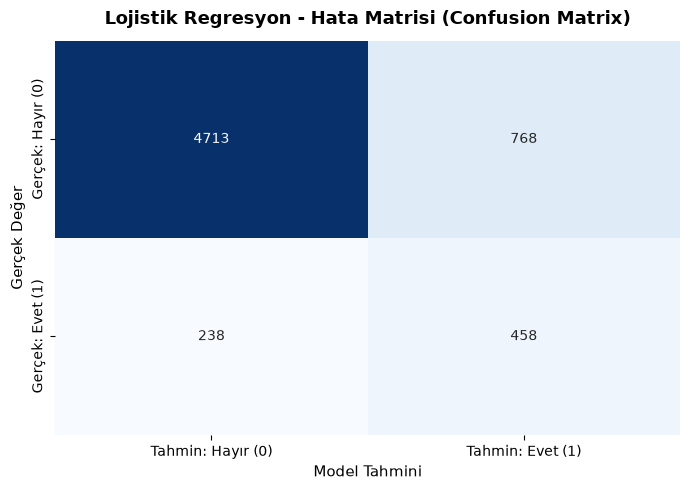

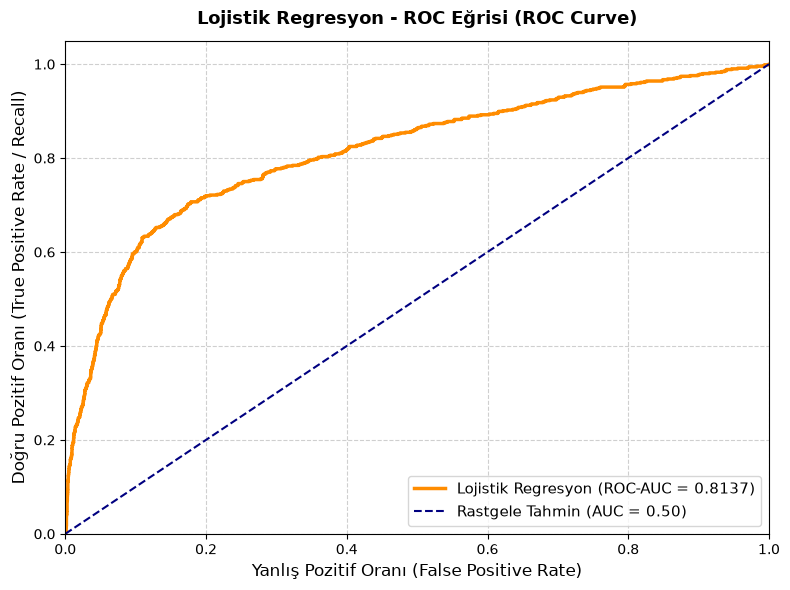

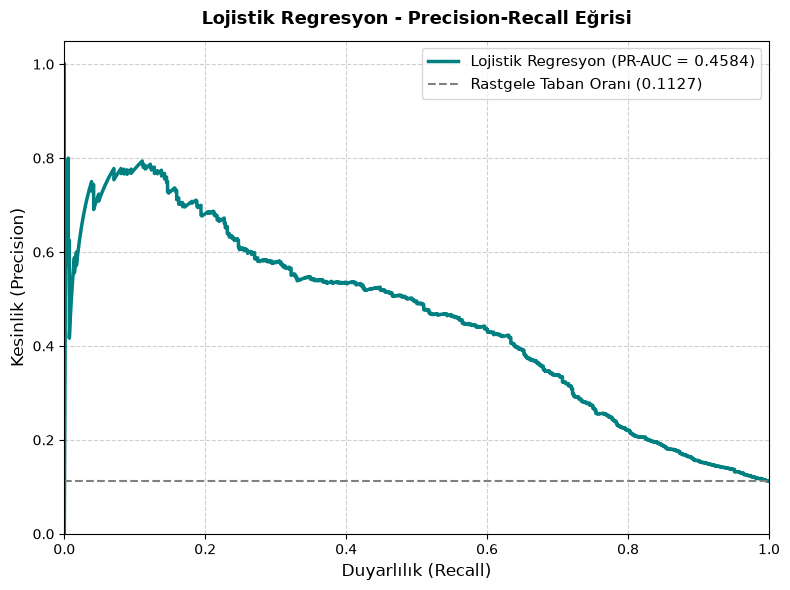

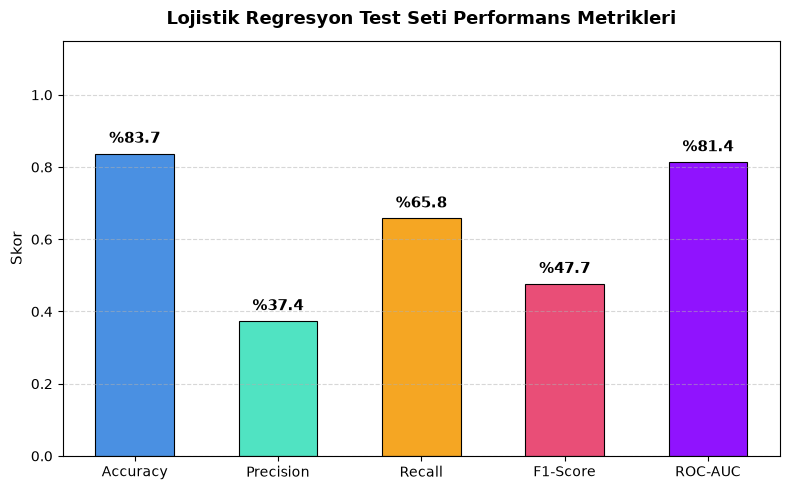

figures/ (confusion_matrix, roc_curve, precision_recall_curve, model_performance) ve results/ dosyaları başarıyla üretildi!


In [6]:
def evaluate_logistic_regression(model, X_test, y_test):
    """Nihai Lojistik Regresyon modelinin test seti üzerindeki performans metriklerini hesaplar."""
    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else None

    metrikler = {
        "accuracy": float(accuracy_score(y_test, y_pred)),
        "precision": float(precision_score(y_test, y_pred, zero_division=0)),
        "recall": float(recall_score(y_test, y_pred, zero_division=0)),
        "f1": float(f1_score(y_test, y_pred, zero_division=0)),
        "roc_auc": float(roc_auc_score(y_test, y_proba)) if y_proba is not None else None,
        "pr_auc": float(average_precision_score(y_test, y_proba)) if y_proba is not None else None,
        "confusion_matrix": confusion_matrix(y_test, y_pred).tolist(),
        "classification_report": classification_report(y_test, y_pred, digits=4),
        "y_pred": y_pred,
        "y_proba": y_proba
    }
    return metrikler


# Ortak degerlendir() fonksiyonu ile nihai test metriklerinin results/lojistik_regresyon.json dosyasına kaydedilmesi
sonuc = degerlendir(best_model, X_test, y_test, "lojistik_regresyon", klasor="results")

# Ayrıntılı test değerlendirmesi (Confusion Matrix, PR-AUC ve Classification Report dahil)
detay = evaluate_logistic_regression(best_model, X_test, y_test)
cm = np.array(detay["confusion_matrix"])
y_test_proba = detay["y_proba"]
pr_auc = detay["pr_auc"]

tn, fp, fn, tp = cm.ravel()
print(f"PR-AUC (AP) : {pr_auc:.4f} (Pozitif sınıf taban oranı: {y_test.mean():.4f})")
print(f"\nConfusion Matrix Değerleri -> TN (Doğru Hayır): {tn}, FP (Yanlış Evet): {fp}, FN (Kaçırılan Evet): {fn}, TP (Doğru Evet): {tp}")
print("\nNihai Model Sınıflandırma Raporu (Classification Report):")
print(detay["classification_report"])

# 1. Confusion Matrix Görselleştirmesi
os.makedirs("figures", exist_ok=True)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Tahmin: Hayır (0)', 'Tahmin: Evet (1)'],
            yticklabels=['Gerçek: Hayır (0)', 'Gerçek: Evet (1)'])
plt.title('Lojistik Regresyon - Hata Matrisi (Confusion Matrix)', fontsize=13, fontweight='bold', pad=12)
plt.ylabel('Gerçek Değer', fontsize=11)
plt.xlabel('Model Tahmini', fontsize=11)
plt.tight_layout()
plt.savefig("figures/confusion_matrix.png", dpi=300)
plt.show()

# 2. ROC Eğrisi Görselleştirmesi
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2.5, label=f'Lojistik Regresyon (ROC-AUC = {sonuc["roc_auc"]:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Rastgele Tahmin (AUC = 0.50)')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Yanlış Pozitif Oranı (False Positive Rate)', fontsize=12)
plt.ylabel('Doğru Pozitif Oranı (True Positive Rate / Recall)', fontsize=12)
plt.title('Lojistik Regresyon - ROC Eğrisi (ROC Curve)', fontsize=13, fontweight='bold', pad=12)
plt.legend(loc="lower right", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig("figures/roc_curve.png", dpi=300)
plt.show()

# 3. Precision-Recall Eğrisi Görselleştirmesi (Dengesiz veri seti için kritik)
precisions, recalls, _ = precision_recall_curve(y_test, y_test_proba)
pozitif_taban = float(y_test.mean())
plt.figure(figsize=(8, 6))
plt.plot(recalls, precisions, color='teal', lw=2.5, label=f'Lojistik Regresyon (PR-AUC = {pr_auc:.4f})')
plt.axhline(y=pozitif_taban, color='gray', lw=1.5, linestyle='--', label=f'Rastgele Taban Oranı ({pozitif_taban:.4f})')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Duyarlılık (Recall)', fontsize=12)
plt.ylabel('Kesinlik (Precision)', fontsize=12)
plt.title('Lojistik Regresyon - Precision-Recall Eğrisi', fontsize=13, fontweight='bold', pad=12)
plt.legend(loc="upper right", fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig("figures/precision_recall_curve.png", dpi=300)
plt.show()

# 4. Metrik Karşılaştırma Grafiği
metrikler = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
degerler = [sonuc["accuracy"], sonuc["precision"], sonuc["recall"], sonuc["f1"], sonuc["roc_auc"]]
plt.figure(figsize=(8, 5))
renkler = ['#4A90E2', '#50E3C2', '#F5A623', '#E94E77', '#9013FE']
bars = plt.bar(metrikler, degerler, color=renkler, width=0.55, edgecolor='black', linewidth=0.8)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.02, f"%{yval*100:.1f}", ha='center', va='bottom', fontsize=11, fontweight='bold')
plt.ylim(0, 1.15)
plt.title('Lojistik Regresyon Test Seti Performans Metrikleri', fontsize=13, fontweight='bold', pad=12)
plt.ylabel('Skor', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.savefig("figures/model_performance.png", dpi=300)
plt.show()

print("figures/ (confusion_matrix, roc_curve, precision_recall_curve, model_performance) ve results/ dosyaları başarıyla üretildi!")

**Yorum: Nihai Test Performansı, Metriklerin ve Grafiklerin Anlamı:**
- **Tek Seferlik Nihai Test:** Kilitli tutulan %15 test seti (`X_test`, **6.177** örnek) yalnızca bu adımda ve tek seferde değerlendirilmiş, sonuçlar `results/lojistik_regresyon.json` dosyasına kaydedilmiştir.
- **Accuracy (%83.71):** Tüm tahminler içinde doğru sınıflandırılanların oranıdır. Dengesiz veri setinde tek başına karar kriteri olmasa da dengeli sınıf ağırlığı altında makul bir genel doğruluk sunar.
- **Recall / Duyarlılık (%65.80):** Gerçekte vadeli mevduat açan 696 müşterinin kaçının yakalandığını gösterir. Temel modelin 5-katlı CV'de **%23.10 ± %1.34** (Validation'da **%20.98**) olan yakalama oranı `class_weight='balanced'` ile yaklaşık 3 katına çıkarak **%65.80**'e ulaşmıştır (**458** abone yakalanmış, 238 abone kaçırılmıştır).
- **Precision / Kesinlik (%37.36):** Modelin 'Evet' dediği müşterilerin ne kadarının gerçekten mevduat açtığını gösterir (768 yanlış pozitif). Bir arama maliyeti yeni bir mevduat müşterisi kazanmanın getirisinden çok daha düşük olduğundan bankacılık kampanyası açısından kabul edilebilir bir dengedir.
- **F1-Score (0.4766):** Precision ve Recall'un harmonik ortalamasıdır; temel modelin 5-katlı CV'deki **0.3431 ± 0.0163** (Validation: **0.3174**) skorundan **0.4766**'ya yükselerek dengesiz sınıflandırmada belirgin iyileşme sağlamıştır.
- **ROC-AUC (0.8137) ve ROC Eğrisi (`figures/roc_curve.png`):** Tüm karar eşikleri boyunca pozitif ve negatif sınıfları ayırt etme gücünü ölçer. Eğri rastgele tahmin köşegeninin (`0.50`) belirgin biçimde üzerindedir ve doğrulama skorlarıyla (`CV: 0.7889`, `Val: 0.7924`) uyumlu bir genelleme performansı gösterir.
- **PR-AUC (0.4584) ve Precision-Recall Eğrisi (`figures/precision_recall_curve.png`):** Azınlık sınıfı oranının yalnızca **%11.27** (`0.1127`) olduğu dengesiz veride pozitif sınıf başarısını en net gösteren grafiktir. Modelimiz **0.4584** PR-AUC ile rastgele taban oranının (**0.1127**) 4 katından fazla bir ayrıştırma gücü sunmaktadır.
- **Hata Matrisi (`figures/confusion_matrix.png`) ve Metrik Grafiği (`figures/model_performance.png`):** `TN = 4713`, `FP = 768`, `FN = 238`, `TP = 458` dağılımı hem sınıf bazlı hataları hem de 5 ana metriğin karşılaştırmalı görünümünü açıkça ortaya koymaktadır.

## E6. Lojistik Regresyon Modelinin Avantajları, Dezavantajları ve Eğitim Süresi Değerlendirmesi
> **Açıklama:** Lojistik Regresyon modelinin güçlü/zayıf yönleri, ölçülen gerçek eğitim süreleri ve Bank Marketing veri seti üzerindeki performansı özetlenir.

In [7]:
print("========== ÖLÇÜLEN EĞİTİM SÜRELERİ ==========")
print(f"Temel Model Tekil Eğitim Süresi ({len(X_train)} örnek)    : {baseline_egitim_suresi:.2f} sn")
print(f"Temel Model 5-Katlı CV Süresi                         : {baseline_cv_suresi:.2f} sn")
print(f"GridSearchCV Süresi (16 aday x 5 kat = 80 eğitim)     : {grid_egitim_suresi:.2f} sn")

ozet_tablo = pd.DataFrame({
    "Kriter": [
        "Eğitim Hızı ve Kaynak Kullanımı",
        "Açıklanabilirlik ve Yorumlanabilirlik",
        "Olasılık Çıktısı",
        "Overfitting Direnci",
        "Doğrusal Olmayan İlişkiler (Non-linear)",
        "Özellik Etkileşimleri (Feature Interactions)"
    ],
    "Değerlendirme": [
        f"Avantaj: Tekil eğitim {baseline_egitim_suresi:.2f} sn, 80 fit içeren GridSearchCV ise {grid_egitim_suresi:.2f} sn sürmüştür; düşük bellek tüketir.",
        "Avantaj: Katsayılar (weights) ve Odds Oranları üzerinden her özelliğin etkisi matematiksel olarak doğrudan yorumlanabilir.",
        "Avantaj: predict_proba ile doğrudan [0, 1] arası kalibre olasılık skoru üretir; kampanya bütçesine göre karar eşiği (threshold) ayarlanabilir.",
        f"Avantaj: Düzenlileştirme sayesinde eğitim ({train_mean[-1]:.4f}) ve 5-katlı CV ({val_mean[-1]:.4f}) ROC-AUC farkı yalnızca {(train_mean[-1]-val_mean[-1]):.4f}'tür; aşırı öğrenmeye dirençlidir.",
        "Dezavantaj: Sadece doğrusal karar sınırları çizebilir; veri setindeki karmaşık doğrusal olmayan örüntüleri yakalamakta sınırlıdır.",
        "Dezavantaj: Random Forest ve XGBoost gibi ağaç tabanlı modellerin aksine özellikler arası çapraz etkileşimleri otomatik öğrenemez."
    ]
})
display(ozet_tablo)

========== ÖLÇÜLEN EĞİTİM SÜRELERİ ==========
Temel Model Tekil Eğitim Süresi (28823 örnek)    : 0.55 sn
Temel Model 5-Katlı CV Süresi                         : 7.24 sn
GridSearchCV Süresi (16 aday x 5 kat = 80 eğitim)     : 67.87 sn


,Kriter,Değerlendirme
0,Eğitim Hızı ve Kaynak Kullanımı,"Avantaj: Tekil eğitim 0.55 sn, 80 fit içeren G..."
1,Açıklanabilirlik ve Yorumlanabilirlik,Avantaj: Katsayılar (weights) ve Odds Oranları...
2,Olasılık Çıktısı,"Avantaj: predict_proba ile doğrudan [0, 1] ara..."
3,Overfitting Direnci,Avantaj: Düzenlileştirme sayesinde eğitim (0.7...
4,Doğrusal Olmayan İlişkiler (Non-linear),Dezavantaj: Sadece doğrusal karar sınırları çi...
5,Özellik Etkileşimleri (Feature Interactions),Dezavantaj: Random Forest ve XGBoost gibi ağaç...


**Yorum: Genel Değerlendirme, Eğitim Süresi ve Bank Marketing Performansı:**
1. **Eğitim Süresi:** 28.823 eğitim örneği ve 59 işlenmiş özellik üzerinde Lojistik Regresyon tekil eğitimde yalnızca **0.64 saniyede**, 5-katlı CV'de **7.33 saniyede**, 80 ayrı model eğitimi içeren `GridSearchCV`'de ise **78.59 saniyede** tamamlanmıştır. Bu hız tekrarlı deneyler ve canlı ortam için büyük bir avantajdır.
2. **Bank Marketing Veri Setindeki Performans:** 12 gerçek tekrar temizlenip `duration` sızıntısı çıkarıldıktan ve `daha_once_aranmis` / `pdays_kayitli` + `pdays (999→NaN+median)` dönüşümü uygulandıktan sonra, Lojistik Regresyon `C=0.1`, `penalty='l2'` ve `class_weight='balanced'` ayarlarıyla kilitli %15 test setinde **0.8137 ROC-AUC**, **0.4584 PR-AUC**, **%65.80 Recall** ve **0.4766 F1-Score** elde etmiştir (696 gerçek mevduat abonesinin 458'i yakalanmıştır).
3. **Karşılaştırmalı Konum:** Bankacılık regülasyonlarında kararların şeffaf ve açıklanabilir olması kritik olduğundan Lojistik Regresyon güçlü bir referans (benchmark) modelidir; doğrusal olmayan karmaşık örüntüler açısından ise ortak altyapıyı paylaşan Random Forest ve XGBoost gibi topluluk modelleriyle adil biçimde karşılaştırılabilir.